# Recipe: Non-spherical grains: hollow spheres (DHS)

Astronomical silicate grains in a ring around a Sun-like star, once as Mie spheres and once as DHS with f_max = 0.8 (grain_shape = 'dhs'): the SED near the 10 and 20 micron silicate bands and the degree of polarisation against scattering angle at 1.6 micron.

**Files:** model defined in Python  
**Run time:** about 15 s  
**Manual:** Sect. 16.8 of `docs/manual/dms_manual.pdf`. The same code as a script: `python3 examples/recipes/hollow_spheres.py`.

In [1]:
# Setup: this notebook lives in examples/recipes/ of the repository
import os, sys
if "REPO" not in globals():
    REPO = os.environ.get("DMS_REPO") or os.path.abspath(os.path.join("..", ".."))
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
os.chdir(REPO)                                        # input files and cache/ are relative to the root
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__)

DMS 2.2.1


In [2]:
base = dms.Model(
    run={"mode": "sed", "emission": "both", "load_optics": True, "save_optics": True},
    star={"teff": 5800.0, "radius": 1.0, "mass": 1.0, "distance": 20.0},
    disk={"r_in": 10.0, "r_out": 30.0, "dust_mass": 1e-9, "inclination": 88.0},
    wavelengths={"lambda_min": 1.6, "lambda_max": 100.0, "n_lambda": 60},
    dust={"n_components": 1, "optical_data": "astrosilicate_draine03_862", "bulk_density": 3.5,
          "a_min": 0.3, "a_max": 100.0, "q": 3.5, "n_sizes": 75})
res = {}
for shape in ("sphere", "dhs"):
    m = base.copy().update(run={"optics_cache_name": f"recipe_{shape}"},
                           dust={"grain_shape": shape, "dhs_fmax": 0.8})
    res[shape] = m.run()
    print(f"{shape:6s}  f_d = {res[shape].f_d:.3e}")

sphere  f_d = 5.067e-04


dhs     f_d = 5.637e-04


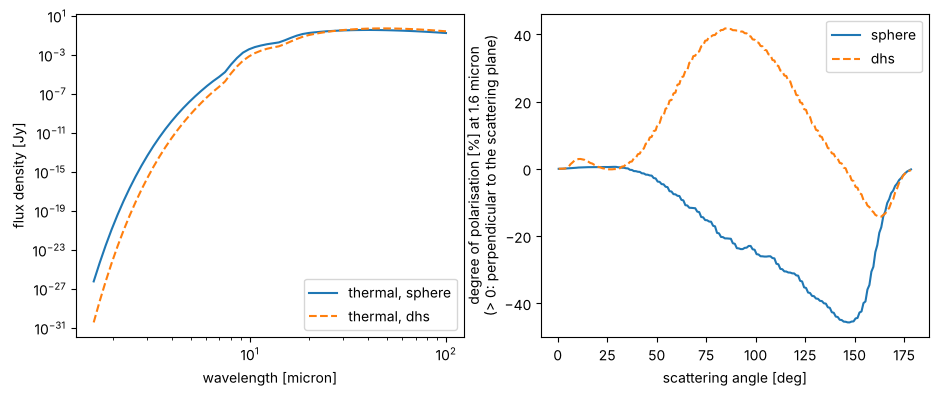

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
lam = res["sphere"].wavelength
for shape, ls in (("sphere", "-"), ("dhs", "--")):
    ax[0].loglog(lam, res[shape].sed["thermal"], ls, label=f"thermal, {shape}")
    th, fs, fp = res[shape].phase_curve(0)                     # 1.6 micron, whole disk
    with np.errstate(invalid="ignore", divide="ignore"):
        ax[1].plot(th, 100 * fp / fs, ls, label=shape)
ax[0].set_xlabel("wavelength [micron]"); ax[0].set_ylabel("flux density [Jy]"); ax[0].legend()
ax[1].set_xlabel("scattering angle [deg]")
ax[1].set_ylabel("degree of polarisation [%] at 1.6 micron\n(> 0: perpendicular to the scattering plane)")
ax[1].legend()
plt.show()

**Result.** The hollow spheres absorb more per unit mass (f_d = 5.6e-04 against 5.1e-04) and polarise very differently: the compact spheres reach −40 % (parallel to the scattering plane) at 150°, the hollow spheres +40 % near 90°.